In [1]:
import pandas as pd

print("Python is working!")
print("Pandas version:", pd.__version__)

Python is working!
Pandas version: 3.1.0


In [2]:
import pandas as pd
df = pd.read_csv('../data/hotel_bookings.csv')
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
print("Rows:",df.shape[0])
print("Columns:",df.shape[1])

Rows: 119390
Columns: 32


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [5]:
missing = df.isnull().sum()
missing

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [6]:
missing[missing>0].sort_values(ascending=False)

company     112593
agent        16340
country        488
children         4
dtype: int64

In [7]:
df["is_canceled"].value_counts()

is_canceled
0    75166
1    44224
Name: count, dtype: int64

In [8]:
df["is_canceled"].value_counts(normalize=True) * 100

is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns 

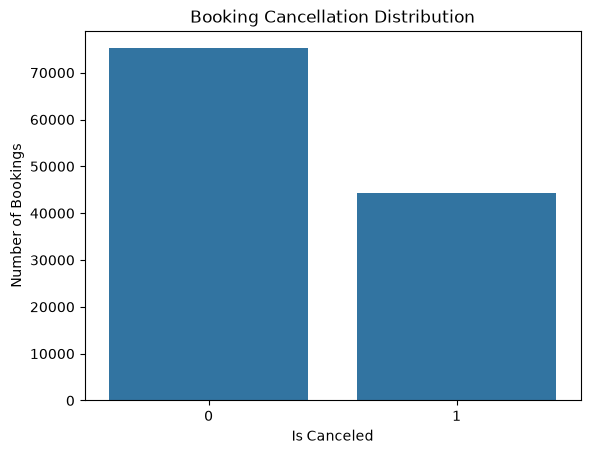

In [10]:
sns.countplot(data=df,x="is_canceled")
plt.title("Booking Cancellation Distribution")
plt.xlabel("Is Canceled")
plt.ylabel("Number of Bookings")
plt.show()


In [11]:
# Missing Values
print(df.isnull().sum()[df.isnull().sum() > 0])

# Target Distribution
print(df["is_canceled"].value_counts(normalize=True) * 100)

# Dataset Information
df.info()

children         4
country        488
agent        16340
company     112593
dtype: int64
is_canceled
0    62.958372
1    37.041628
Name: proportion, dtype: float64
<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  

In [12]:
# Create a copy of the original dataset
df_clean = df.copy()

# Remove columns not suitable for our first model
columns_to_drop = [
    "company",
    "reservation_status",
    "reservation_status_date",
    "assigned_room_type",
    "booking_changes",
    "days_in_waiting_list"
]
df_clean = df_clean.drop(columns=columns_to_drop)
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (119390, 32)
Cleaned shape: (119390, 26)


In [13]:
missing = df_clean.isnull().sum()
print(missing[missing>0])
print("\nData types:")
print(df_clean.dtypes.value_counts())

children        4
country       488
agent       16340
dtype: int64

Data types:
int64      14
str         9
float64     3
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=["is_canceled"])
y = df_clean['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,
    stratify=y)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (95512, 25)
X_test: (23878, 25)
y_train: (95512,)
y_test: (23878,)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

numerical_transformer = Pipeline(steps = [
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_transformer = Pipeline(steps = [
    ("imputer",SimpleImputer(strategy="constant",fill_value="Unknown")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num",numerical_transformer,numerical_cols),
        ("cat",categorical_transformer,categorical_cols)
    ]
)

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 16
Categorical columns: 9


/var/folders/vb/9h30d9q17l5gkq70btnr9zzc0000gn/T/ipykernel_25122/1836375932.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline(steps=[
    ("preprocessor",preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

model.fit(X_train,y_train)

print("Model trained successfully!")

Model trained successfully!


In [17]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.8116257643018678
Precision: 0.807034891933889
Recall: 0.6459016393442623
F1 Score: 0.7175332830946998

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.91      0.86     15033
           1       0.81      0.65      0.72      8845

    accuracy                           0.81     23878
   macro avg       0.81      0.78      0.79     23878
weighted avg       0.81      0.81      0.81     23878



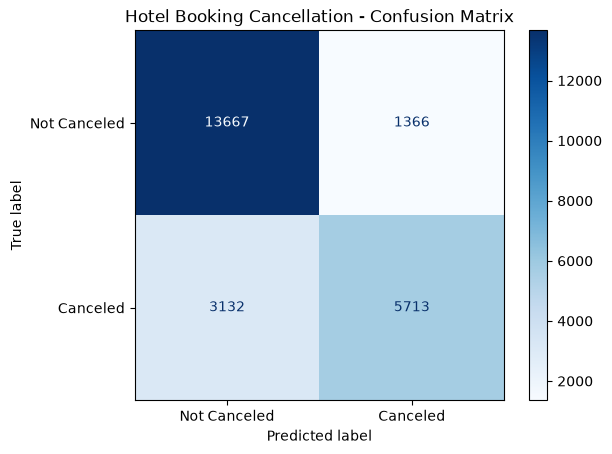

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Canceled", "Canceled"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Hotel Booking Cancellation - Confusion Matrix")
plt.show()

In [19]:
for col in X_train.columns:
    print(col)

hotel
lead_time
arrival_date_year
arrival_date_month
arrival_date_week_number
arrival_date_day_of_month
stays_in_weekend_nights
stays_in_week_nights
adults
children
babies
meal
country
market_segment
distribution_channel
is_repeated_guest
previous_cancellations
previous_bookings_not_canceled
reserved_room_type
deposit_type
agent
customer_type
adr
required_car_parking_spaces
total_of_special_requests


In [20]:
df_v2 = df_clean.drop(columns=["required_car_parking_spaces","total_of_special_requests"]).copy()

df_v2["agent"] = df_v2["agent"].astype("string").fillna("Unknown")
df_v2["agent"] = df_v2["agent"].astype(str)

X = df_v2.drop(columns=["is_canceled"])
y = df_v2["is_canceled"]

print("Features:", X.shape[1])
print("Rows:", X.shape[0])

Features: 23
Rows: 119390


In [21]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder,StandardScaler

numerical_cols = X_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()

numerical_transformer = Pipeline(steps = [
    ("imputer",SimpleImputer(strategy="median")),
    ("scaler",StandardScaler())
])

categorical_transformer = Pipeline(steps = [
    ("imputer",SimpleImputer(strategy="constant",fill_value="Unknown")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num",numerical_transformer,numerical_cols),
        ("cat",categorical_transformer,categorical_cols)
    ]
)

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 13
Categorical columns: 10


/var/folders/vb/9h30d9q17l5gkq70btnr9zzc0000gn/T/ipykernel_25122/1836375932.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X_train.select_dtypes(include=['object']).columns.tolist()


In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

model_v2 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model_v2.fit(X_train, y_train)

y_pred_v2 = model_v2.predict(X_test)

print(classification_report(y_test, y_pred_v2))

              precision    recall  f1-score   support

           0       0.80      0.90      0.85     15033
           1       0.79      0.60      0.68      8845

    accuracy                           0.79     23878
   macro avg       0.79      0.75      0.77     23878
weighted avg       0.79      0.79      0.79     23878



In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.74      1.00      0.85     15033
           1       0.98      0.41      0.58      8845

    accuracy                           0.78     23878
   macro avg       0.86      0.70      0.71     23878
weighted avg       0.83      0.78      0.75     23878



In [25]:
from sklearn.model_selection import train_test_split

X_train_new, X_val, y_train_new, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Train:", X_train_new.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (76409, 23)
Validation: (19103, 23)
Test: (23878, 23)


In [26]:
from sklearn import clone

rf_val_model = clone(rf_model)

rf_val_model.fit(X_train_new,y_train_new)

Y_prop  = rf_val_model.predict_proba(X_val)[:, 1]

In [27]:
from sklearn.metrics import precision_score,recall_score,f1_score
import pandas
results = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:
    y_pred = (Y_prop >= threshold).astype(int)
    results.append({
        "Threshold":threshold,
        "Precision": precision_score(y_val,y_pred,zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1": f1_score(y_val, y_pred, zero_division=0)
    })
results_df = pd.DataFrame(results)

print(results_df.round(3))

   Threshold  Precision  Recall     F1
0        0.2      0.514   0.969  0.671
1        0.3      0.632   0.920  0.749
2        0.4      0.766   0.746  0.756
3        0.5      0.986   0.409  0.579
4        0.6      1.000   0.373  0.543


In [28]:
best_row = results_df.loc[results_df["F1"].idxmax()]

print("Best threshold:", best_row["Threshold"])
print("Best validation F1:", best_row["F1"])

Best threshold: 0.4
Best validation F1: 0.755673276540912


In [29]:
from sklearn.base import clone
from sklearn.metrics import classification_report, confusion_matrix

final_model = clone(rf_model)
final_model.fit(X_train,y_train)

test_prob = final_model.predict_proba(X_test)[:, 1]

final_pred = (test_prob >= 0.4).astype(int)

print(classification_report(y_test,final_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, final_pred))

              precision    recall  f1-score   support

           0       0.85      0.87      0.86     15033
           1       0.77      0.75      0.76      8845

    accuracy                           0.82     23878
   macro avg       0.81      0.81      0.81     23878
weighted avg       0.82      0.82      0.82     23878

Confusion Matrix:
[[13062  1971]
 [ 2245  6600]]


In [30]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import make_scorer, f1_score
import pandas as pd

def cancellation_f1(estimator,X,y):
    probabilities = estimator.predict_proba(X)[:,1]
    predictions = (probabilities >= 0.4).astype(int)
    return f1_score(y,predictions)

importance = permutation_importance(
    final_model,
    X_test,
    y_test,
    scoring=cancellation_f1,
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)
feature_importance = pd.DataFrame(
    {
        "Feature" : X_test.columns,
        "Importance": importance.importances_mean
    }
).sort_values("Importance", ascending=False)
print(feature_importance.head(10))

                   Feature  Importance
20                   agent    0.086367
12                 country    0.078532
13          market_segment    0.067711
19            deposit_type    0.053257
1                lead_time    0.051994
21           customer_type    0.042139
0                    hotel    0.030744
22                     adr    0.023482
14    distribution_channel    0.022791
16  previous_cancellations    0.020953


In [31]:
from sklearn.base import clone 
from sklearn.metrics import classification_report

X_train_no_agent = X_train_new.drop(columns=["agent"])
X_val_no_agent = X_val.drop(columns=["agent"])

from sklearn.compose import ColumnTransformer

num_cols = X_train_no_agent.select_dtypes(
    include=["int64","float64"]
).columns.tolist()

cat_cols = X_train_no_agent.select_dtypes(
    include = ["object","string","category"]
).columns.tolist()

preprocessor_no_agent = ColumnTransformer([
    ("num",clone(numerical_transformer),num_cols),
    ("cat",clone(categorical_transformer),cat_cols)
])
rf_no_agent = Pipeline([
    ("preprocessor", preprocessor_no_agent),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])
rf_no_agent.fit(X_train_no_agent, y_train_new)

prob_no_agent = rf_no_agent.predict_proba(X_val_no_agent)[:, 1]
pred_no_agent = (prob_no_agent >= 0.4).astype(int)

print(classification_report(y_val, pred_no_agent))

              precision    recall  f1-score   support

           0       0.85      0.87      0.86     12027
           1       0.77      0.75      0.76      7076

    accuracy                           0.82     19103
   macro avg       0.81      0.81      0.81     19103
weighted avg       0.82      0.82      0.82     19103



In [32]:
from sklearn.metrics import f1_score, recall_score, precision_score

# Original model WITH agent
prob_with_agent = rf_val_model.predict_proba(X_val)[:, 1]
pred_with_agent = (prob_with_agent >= 0.4).astype(int)

# New model WITHOUT agent
prob_without_agent = rf_no_agent.predict_proba(X_val_no_agent)[:, 1]
pred_without_agent = (prob_without_agent >= 0.4).astype(int)

comparison = pd.DataFrame({
    "Model": ["With Agent", "Without Agent"],
    "Precision": [
        precision_score(y_val, pred_with_agent),
        precision_score(y_val, pred_without_agent)
    ],
    "Recall": [
        recall_score(y_val, pred_with_agent),
        recall_score(y_val, pred_without_agent)
    ],
    "F1": [
        f1_score(y_val, pred_with_agent),
        f1_score(y_val, pred_without_agent)
    ]
})

print(comparison.round(4))

           Model  Precision  Recall      F1
0     With Agent     0.7657  0.7459  0.7557
1  Without Agent     0.7652  0.7453  0.7552


In [33]:
#We need to calcaulate the Booking date because we need it to know if the model is able to predict the future bookings

import pandas as pd

df_temporal = df_v2.drop(columns=["agent"]).copy()

# Create arrival date

df_temporal["arrival_date"] = pd.to_datetime(
    df_temporal['arrival_date_year'].astype(str) + "-" +
     df_temporal["arrival_date_month"].astype(str) + "-" +
    df_temporal["arrival_date_day_of_month"].astype(str),
    format="%Y-%B-%d"
)

df_temporal['booking_date'] = (df_temporal['arrival_date'] - pd.to_timedelta(df_temporal["lead_time"], unit="D"))

print(df_temporal[[
    "arrival_date",
    "lead_time",
    "booking_date"
]].head())

print("Earliest booking:", df_temporal["booking_date"].min())
print("Latest booking:", df_temporal["booking_date"].max())

  arrival_date  lead_time booking_date
0   2015-07-01        342   2014-07-24
1   2015-07-01        737   2013-06-24
2   2015-07-01          7   2015-06-24
3   2015-07-01         13   2015-06-18
4   2015-07-01         14   2015-06-17
Earliest booking: 2013-06-24 00:00:00
Latest booking: 2017-08-31 00:00:00


In [34]:
df_temporal = df_temporal.sort_values("booking_date").reset_index(drop=True)

n = len(df_temporal)

train_end = int(n*0.7)
val_end = int(n*0.85)

train_cutoff = df_temporal.loc[train_end,"booking_date"]
val_cutoff = df_temporal.loc[val_end,"booking_date"]

train_df = df_temporal[df_temporal['booking_date'] < train_cutoff].copy()
val_df = df_temporal[
    (df_temporal["booking_date"] >= train_cutoff) &
    (df_temporal["booking_date"] < val_cutoff)
].copy()
test_df = df_temporal[df_temporal['booking_date'] >= val_cutoff].copy()

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "| Rows:", len(data),
        "| From:", data["booking_date"].min().date(),
        "| To:", data["booking_date"].max().date(),
        "| Cancellation rate:",
        round(data["is_canceled"].mean() * 100, 2), "%"
    )

Train | Rows: 83506 | From: 2013-06-24 | To: 2016-11-05 | Cancellation rate: 37.98 %
Validation | Rows: 17820 | From: 2016-11-06 | To: 2017-02-02 | Cancellation rate: 39.89 %
Test | Rows: 18064 | From: 2017-02-03 | To: 2017-08-31 | Cancellation rate: 29.9 %


In [35]:
# Columns not used for prediction
drop_cols = ["is_canceled", "booking_date", "arrival_date"]

X_train_time = train_df.drop(columns=drop_cols)
y_train_time = train_df["is_canceled"]

X_val_time = val_df.drop(columns=drop_cols)
y_val_time = val_df["is_canceled"]

X_test_time = test_df.drop(columns=drop_cols)
y_test_time = test_df["is_canceled"]

print("Training:", X_train_time.shape)
print("Validation:", X_val_time.shape)
print("Testing:", X_test_time.shape)

Training: (83506, 22)
Validation: (17820, 22)
Testing: (18064, 22)


### Feature Availability Assumptions

Prediction time: At booking creation.

- Excluded post-booking features such as reservation_status, reservation_status_date, assigned_room_type, and booking_changes.
- Deposit type and ADR are assumed to reflect values known at booking creation.
- Historical booking features are assumed to contain only information available before the current booking.
- Customer type and distribution channel are assumed to be available at booking creation.

Limitation: The dataset does not independently verify the timestamps of all feature values. These assumptions should be validated before production use.


In [36]:
print(X_train_time.columns.tolist())

['hotel', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type', 'adr']


In [37]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier

num_cols_time = X_train_time.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

cat_cols_time = X_train_time.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

time_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols_time),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols_time)
])

time_model = Pipeline([
    ("preprocessor", time_preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

time_model.fit(X_train_time, y_train_time)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['hotel','lead_time','arrival_date_year',...,'deposit_type', 'customer_type','adr']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='pas

In [38]:
from sklearn.metrics import classification_report, confusion_matrix

val_prob_time = time_model.predict_proba(X_val_time)[:, 1]
val_pred_time = (val_prob_time >= 0.4).astype(int)

print(classification_report(y_val_time, val_pred_time))
print(confusion_matrix(y_val_time, val_pred_time))

              precision    recall  f1-score   support

           0       0.87      0.70      0.77     10711
           1       0.65      0.85      0.73      7109

    accuracy                           0.76     17820
   macro avg       0.76      0.77      0.75     17820
weighted avg       0.78      0.76      0.76     17820

[[7457 3254]
 [1097 6012]]


In [39]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

results_time = []

for threshold in [0.2, 0.3, 0.4, 0.5, 0.6]:
    predictions = (val_prob_time >= threshold).astype(int)

    results_time.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val_time, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val_time, predictions, zero_division=0
        ),
        "F1": f1_score(
            y_val_time, predictions, zero_division=0
        )
    })

results_time_df = pd.DataFrame(results_time)

print(results_time_df.round(3))

best_row = results_time_df.loc[
    results_time_df["F1"].idxmax()
]

print("\nBest Threshold:", best_row["Threshold"])
print("Best Validation F1:", round(best_row["F1"], 3))

   Threshold  Precision  Recall     F1
0        0.2      0.507   0.979  0.668
1        0.3      0.575   0.945  0.715
2        0.4      0.649   0.846  0.734
3        0.5      0.870   0.548  0.672
4        0.6      0.987   0.408  0.578

Best Threshold: 0.4
Best Validation F1: 0.734


In [40]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Predict cancellation probabilities
test_prob_time = time_model.predict_proba(X_test_time)[:, 1]

# Apply threshold selected on validation
test_pred_time = (test_prob_time >= 0.4).astype(int)

print("Classification Report:")
print(classification_report(y_test_time, test_pred_time))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_time, test_pred_time))

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.65      0.74     12663
           1       0.48      0.77      0.60      5401

    accuracy                           0.69     18064
   macro avg       0.68      0.71      0.67     18064
weighted avg       0.76      0.69      0.70     18064


Confusion Matrix:
[[8214 4449]
 [1217 4184]]


In [41]:
drift_summary = pd.DataFrame({
    "Dataset": ["Train", "Validation", "Test"],
    "Avg Lead Time": [
        train_df["lead_time"].mean(),
        val_df["lead_time"].mean(),
        test_df["lead_time"].mean()
    ],
    "Avg ADR": [
        train_df["adr"].mean(),
        val_df["adr"].mean(),
        test_df["adr"].mean()
    ],
    "Cancellation Rate": [
        train_df["is_canceled"].mean(),
        val_df["is_canceled"].mean(),
        test_df["is_canceled"].mean()
    ]
})

print(drift_summary.round(3))

      Dataset  Avg Lead Time  Avg ADR  Cancellation Rate
0       Train        119.095   95.670              0.380
1  Validation         88.230   98.836              0.399
2        Test         49.850  133.268              0.299


In [42]:
print("Earliest arrival:", df_temporal["arrival_date"].min())
print("Latest arrival:", df_temporal["arrival_date"].max())

print("Earliest booking:", df_temporal["booking_date"].min())
print("Latest booking:", df_temporal["booking_date"].max())

Earliest arrival: 2015-07-01 00:00:00
Latest arrival: 2017-08-31 00:00:00
Earliest booking: 2013-06-24 00:00:00
Latest booking: 2017-08-31 00:00:00


In [43]:
monthly_summary = (
    df_temporal
    .assign(
        booking_month=df_temporal["booking_date"].dt.to_period("M")
    )
    .groupby("booking_month")
    .agg(
        bookings=("is_canceled", "size"),
        avg_lead_time=("lead_time", "mean"),
        cancellation_rate=("is_canceled", "mean")
    )
    .reset_index()
)

print(monthly_summary.tail(12).round(3))

   booking_month  bookings  avg_lead_time  cancellation_rate
29       2016-09      4427         85.091              0.342
30       2016-10      4716         98.220              0.315
31       2016-11      5183        102.821              0.426
32       2016-12      5013         87.090              0.440
33       2017-01      7869         85.269              0.341
34       2017-02      5772         71.861              0.351
35       2017-03      3609         61.853              0.296
36       2017-04      2736         46.866              0.311
37       2017-05      2883         34.997              0.290
38       2017-06      1626         24.999              0.282
39       2017-07      1340         17.548              0.270
40       2017-08       730          6.505              0.159


/var/folders/vb/9h30d9q17l5gkq70btnr9zzc0000gn/T/ipykernel_25122/4235349850.py:15: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(monthly_summary.tail(12).round(3))


In [44]:
print(
    test_df["arrival_date"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

arrival_date
2017-02    1197
2017-03    2004
2017-04    2200
2017-05    3044
2017-06    2974
2017-07    3060
2017-08    3585
Freq: M, Name: count, dtype: int64


In [45]:
print("Total bookings:", len(df_temporal))

print(
    "Bookings with lead_time <= 180:",
    (df_temporal["lead_time"] <= 180).sum()
)

print(
    "Bookings with lead_time > 180:",
    (df_temporal["lead_time"] > 180).sum()
)

print(
    "Percentage with lead_time > 180:",
    round(
        (df_temporal["lead_time"] > 180).mean() * 100,
        2
    ),
    "%"
)

Total bookings: 119390
Bookings with lead_time <= 180: 94698
Bookings with lead_time > 180: 24692
Percentage with lead_time > 180: 20.68 %


In [46]:
print(type(time_model))
print(time_model.named_steps.keys())

<class 'sklearn.pipeline.Pipeline'>
dict_keys(['preprocessor', 'classifier'])


In [47]:
import joblib
from pathlib import Path

# Create models folder
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save model and threshold
model_artifact = {
    "model": time_model,
    "threshold": 0.4,
    "features": X_train_time.columns.tolist()
}

joblib.dump(
    model_artifact,
    models_dir / "hotel_cancellation_model.joblib"
)

print("Model saved successfully!")

Model saved successfully!


Use the model


In [48]:
loaded_artifact = joblib.load("../models/hotel_cancellation_model.joblib")

loaded_model = loaded_artifact["model"]
threshold = loaded_artifact["threshold"]

sample_booking = X_test_time.iloc[[0]]

probability = loaded_model.predict_proba(sample_booking)[0,1]

prediction = int(probability >= threshold)

print("Cancellation Probability:", round(probability,3))
print("Prediction:",prediction)

Cancellation Probability: 0.473
Prediction: 1


In [49]:
import json

sample = X_test_time.iloc[0].to_dict()

print(json.dumps(
    {"booking": sample},
    indent=2,
    default=str
))

{
  "booking": {
    "hotel": "City Hotel",
    "lead_time": 37,
    "arrival_date_year": 2017,
    "arrival_date_month": "March",
    "arrival_date_week_number": 11,
    "arrival_date_day_of_month": 12,
    "stays_in_weekend_nights": 2,
    "stays_in_week_nights": 2,
    "adults": 2,
    "children": 0.0,
    "babies": 0,
    "meal": "SC",
    "country": "MAC",
    "market_segment": "Online TA",
    "distribution_channel": "TA/TO",
    "is_repeated_guest": 0,
    "previous_cancellations": 0,
    "previous_bookings_not_canceled": 0,
    "reserved_room_type": "A",
    "deposit_type": "No Deposit",
    "customer_type": "Transient",
    "adr": 76.93
  }
}


In [55]:
type(y_test)

pandas.Series